# CIFAR-10-Bildklassifikation mit ResNet50 und Transfer Learning

Dieses Notebook setzt die Projektvorgabe um: 10.000 CIFAR-10-Trainingsbilder verwenden, sie für ein auf ImageNet vortrainiertes ResNet50 vorverarbeiten, einen eigenen Klassifikationskopf trainieren, das gesamte Modell feinabstimmen (Fine-Tuning) und es auf dem vollständigen CIFAR-10-Testdatensatz evaluieren.

**Erwartete Laufzeit:** In Google Colab eine GPU-Laufzeit verwenden. Die beiden Trainingsphasen mit je 10 Epochen können auf der CPU sehr langsam sein.

**Wichtige Einschränkung:** Der Trainingsdatensatz ist bewusst auf 10.000 Bilder begrenzt, der Testdatensatz umfasst weiterhin 10.000 Bilder. Die Ergebnisse sind in diesem Zusammenhang zu interpretieren.

**Hinweis zur Überarbeitung:** Ein erster Durchlauf erreichte nur 47 % Testgenauigkeit, weil das Fine-Tuning das Modell verschlechtert hat (siehe Analyse in Abschnitt 11). Diese Version behebt die Ursachen: neue Callbacks für jede Phase, eingefrorene Batch-Normalization-Schichten während des Fine-Tunings, leichte Datenaugmentation und eine stratifizierte Validierungsaufteilung.

## 1. Importe und Reproduzierbarkeit

Der Zufalls-Seed von TensorFlow wird gesetzt, damit wiederholte Durchläufe besser vergleichbar sind. Die genauen Ergebnisse können je nach Hardware und TensorFlow-Version trotzdem leicht abweichen. Diagramme und Metriken werden in den Ordner `results/` des Projekts exportiert.

In [1]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.datasets import cifar10

SEED = 42
tf.keras.utils.set_random_seed(SEED)

# Lokal läuft das Notebook aus notebooks/, in Colab aus /content.
RESULTS_DIR = Path("../results") if Path("../README.md").exists() else Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

print(f"TensorFlow: {tf.__version__}")
print(f"Verfügbare GPUs: {tf.config.list_physical_devices('GPU')}")
print(f"Ergebnisordner: {RESULTS_DIR.resolve()}")

TensorFlow: 2.21.0
Verfügbare GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Ergebnisordner: /content/results


## 2. CIFAR-10 laden und Stichprobe ziehen

CIFAR-10 enthält 50.000 Trainings- und 10.000 Testbilder. Die Projektvorgabe wird hier einmalig und nur auf die Trainingsdaten angewendet. Eine stratifizierte Stichprobe hält die Klassenverteilung ausgeglichen und begrenzt gleichzeitig die Laufzeit. Die Klassennamen bleiben auf Englisch, wie im Originaldatensatz.

In [2]:
CLASS_NAMES = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]
TRAIN_SAMPLES = 10_000

(all_train_images, all_train_labels), (test_images, test_labels) = cifar10.load_data()
all_train_labels = all_train_labels.reshape(-1)
test_labels = test_labels.reshape(-1)

rng = np.random.default_rng(SEED)
selected_indices = []
samples_per_class = TRAIN_SAMPLES // len(CLASS_NAMES)
for class_id in range(len(CLASS_NAMES)):
    class_indices = np.flatnonzero(all_train_labels == class_id)
    selected_indices.extend(rng.choice(class_indices, samples_per_class, replace=False))
selected_indices = np.asarray(selected_indices)
rng.shuffle(selected_indices)

train_images = all_train_images[selected_indices]
train_labels = all_train_labels[selected_indices]

print(f"Trainingsbilder: {train_images.shape}")
print(f"Trainingslabels: {train_labels.shape}")
print(f"Testbilder: {test_images.shape}")
print(f"Testlabels: {test_labels.shape}")
print("Trainingsbilder pro Klasse:", np.bincount(train_labels, minlength=len(CLASS_NAMES)))


170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 3424s 20us/step
Trainingsbilder: (10000, 32, 32, 3)
Trainingslabels: (10000,)
Testbilder: (10000, 32, 32, 3)
Testlabels: (10000,)
Trainingsbilder pro Klasse: [1000 1000 1000 1000 1000 1000 1000 1000 1000 1000]


## 3. Daten ansehen

Die Bilder sind RGB-Arrays mit der Form `(32, 32, 3)`. Die folgenden Beispiele dienen als visuelle Plausibilitätsprüfung vor der Vorverarbeitung.

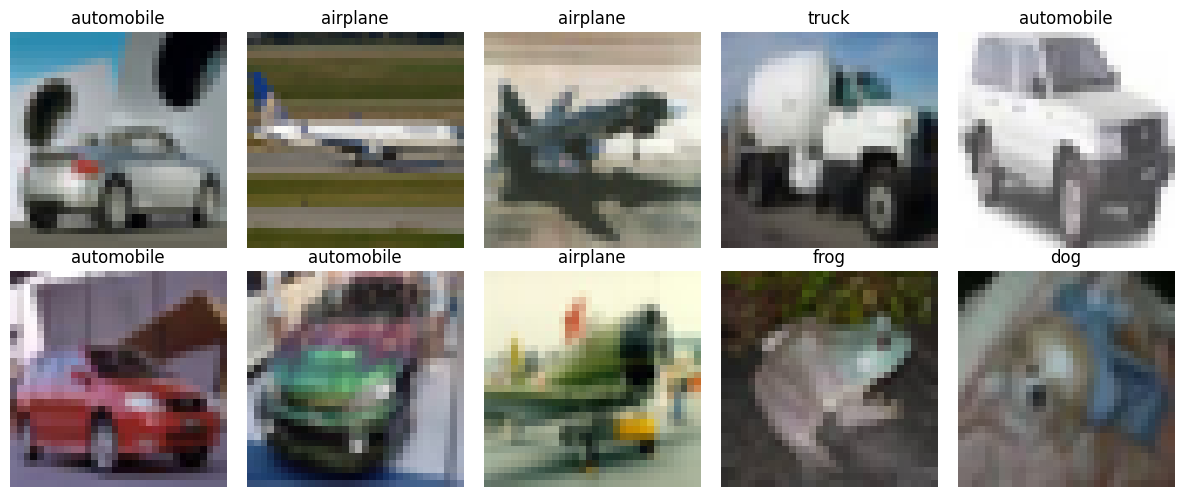

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for image, label, ax in zip(train_images[:10], train_labels[:10], axes.flat):
    ax.imshow(image)
    ax.set_title(CLASS_NAMES[label])
    ax.axis("off")
plt.tight_layout()


## 4. Bilder vorverarbeiten und Datensätze erstellen

ResNet50 wurde auf ImageNet mit einer modellspezifischen Vorverarbeitung trainiert. `preprocess_input` wandelt die RGB-Pixelwerte in die Darstellung um, die das vortrainierte Netz erwartet. CIFAR-10-Bilder haben bereits die geforderte Größe von 32x32 Pixeln, daher ist keine Größenänderung nötig.

Die Validierungsdaten stammen ausschließlich aus der Trainingsstichprobe, mit genau 200 Bildern pro Klasse, damit die Validierungsgenauigkeit keine Klasse bevorzugt. Der Testdatensatz bleibt bis zur abschließenden Evaluation unberührt.

In [4]:
train_images_prepared = preprocess_input(train_images.astype("float32"))
test_images_prepared = preprocess_input(test_images.astype("float32"))

# Stratifizierte Aufteilung: Die Stichprobe ist bereits gemischt, daher sind die ersten 200 Bilder jeder Klasse eine Zufallsauswahl.
VALIDATION_PER_CLASS = 200
validation_mask = np.zeros(len(train_labels), dtype=bool)
for class_id in range(len(CLASS_NAMES)):
    class_positions = np.flatnonzero(train_labels == class_id)
    validation_mask[class_positions[:VALIDATION_PER_CLASS]] = True

validation_images = train_images_prepared[validation_mask]
validation_labels = train_labels[validation_mask]
fit_images = train_images_prepared[~validation_mask]
fit_labels = train_labels[~validation_mask]

BATCH_SIZE = 64
AUTOTUNE = tf.data.AUTOTUNE

train_dataset = tf.data.Dataset.from_tensor_slices((fit_images, fit_labels))
train_dataset = train_dataset.shuffle(len(fit_images), seed=SEED).batch(BATCH_SIZE).prefetch(AUTOTUNE)
validation_dataset = tf.data.Dataset.from_tensor_slices((validation_images, validation_labels))
validation_dataset = validation_dataset.batch(BATCH_SIZE).prefetch(AUTOTUNE)
test_dataset = tf.data.Dataset.from_tensor_slices((test_images_prepared, test_labels))
test_dataset = test_dataset.batch(BATCH_SIZE).prefetch(AUTOTUNE)

print("Trainingsbilder (Fit):", len(fit_images))
print("Validierungsbilder:", len(validation_images))
print("Validierungsbilder pro Klasse:", np.bincount(validation_labels, minlength=len(CLASS_NAMES)))
print("Wertebereich nach Vorverarbeitung:", train_images_prepared.min(), train_images_prepared.max())

Trainingsbilder (Fit): 8000
Validierungsbilder: 2000
Validierungsbilder pro Klasse: [200 200 200 200 200 200 200 200 200 200]
Wertebereich nach Vorverarbeitung: -123.68 151.061


## 5. Transfer-Learning-Modell aufbauen

Die Faltungsschichten von ResNet50 liefern die auf ImageNet gelernten Merkmale. Der eigene Kopf besteht aus Global Average Pooling, einer regularisierten Dense-Schicht und einer Softmax-Ausgabe mit zehn Klassen. In der ersten Trainingsphase ist die Basis eingefroren, sodass nur der neue Klassifikator lernt.

Zwei Ergänzungen greifen auf, was der erste Durchlauf gezeigt hat:

- **Datenaugmentation** (horizontales Spiegeln und kleine Verschiebungen) wird nur während des Trainings angewendet. Im ersten Durchlauf erreichte der Kopf 88 % Trainingsgenauigkeit, aber nur 63 % Validierungsgenauigkeit (letzte Kopf-Epoche 8), er hat also die 8.000 Trainingsbilder auswendig gelernt.
- **`IMAGE_SIZE`** steuert einen optionalen Hochskalierungsschritt. ResNet50 verkleinert seine Eingabe um den Faktor 32, ein 32x32-Bild wird also zu einer einzigen 1x1-Merkmalskarte mit sehr wenig räumlicher Information. Die Vorgabe verlangt 32x32, daher ist das der Standardwert. Ein Wert von 96 verbessert die Genauigkeit meist deutlich, macht das Training aber etwa neunmal langsamer.

In [5]:
IMAGE_SIZE = 32

data_augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomTranslation(0.1, 0.1),
], name="augmentation")

base_model = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3)
)
base_model.trainable = False

inputs = layers.Input(shape=(32, 32, 3))
features = data_augmentation(inputs)
if IMAGE_SIZE != 32:
    features = layers.Resizing(IMAGE_SIZE, IMAGE_SIZE)(features)
features = base_model(features, training=False)
features = layers.GlobalAveragePooling2D()(features)
features = layers.Dense(256, activation="relu")(features)
features = layers.Dropout(0.4)(features)
outputs = layers.Dense(len(CLASS_NAMES), activation="softmax")(features)
model = models.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
model.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 1, 1, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,114,826 (91.99 MB)

 Trainable params: 527,114 (2.01 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

## 6. Klassifikationskopf trainieren

In dieser Phase wird nur der zufällig initialisierte Kopf aktualisiert. Eine Lernratenreduktion und Early Stopping verhindern unnötiges Training, wenn sich die Validierungsleistung nicht mehr verbessert. Das vorgegebene Maximum sind 10 Epochen.

Für jede Phase werden neue Callback-Objekte erzeugt. Im ersten Durchlauf teilten sich beide Phasen eine Callback-Liste: Early Stopping verglich das Fine-Tuning noch mit dem besten Validierungsverlust der Kopf-Phase, brach das Fine-Tuning nach 4 Epochen ab und stellte keine Gewichte wieder her.

In [6]:
def make_callbacks():
    return [
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.2, patience=2, min_lr=1e-6
        ),
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=4, restore_best_weights=True
        )
    ]


def count_trainable_parameters(model):
    return sum(int(np.prod(weight.shape)) for weight in model.trainable_weights)


print(f"Trainierbare Parameter (Kopf-Phase): {count_trainable_parameters(model):,}")

head_history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=10,
    callbacks=make_callbacks()
)

Trainierbare Parameter (Kopf-Phase): 527,114
Epoch 1/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 17s 49ms/step - accuracy: 0.4296 - loss: 1.9606 - val_accuracy: 0.5480 - val_loss: 1.2977 - learning_rate: 0.0010
Epoch 2/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - accuracy: 0.5346 - loss: 1.3569 - val_accuracy: 0.5630 - val_loss: 1.2281 - learning_rate: 0.0010
Epoch 3/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - accuracy: 0.5656 - loss: 1.2291 - val_accuracy: 0.6085 - val_loss: 1.1649 - learning_rate: 0.0010
Epoch 4/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.5880 - loss: 1.1750 - val_accuracy: 0.6020 - val_loss: 1.1506 - learning_rate: 0.0010
Epoch 5/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - accuracy: 0.6104 - loss: 1.1156 - val_accuracy: 0.6045 - val_loss: 1.1636 - learning_rate: 0.0010
Epoch 6/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - accuracy: 0.6166 - loss: 1.0788 - val_accuracy: 0.6260 - val_loss: 1.1052 - learning_rate: 0.0010
Epoch 7/10
125/125 ━━━━━━━━━━━━━━━━━

## 7. Vortrainierte Basis feinabstimmen

Die Basis wird nun freigegeben und mit einer deutlich kleineren Lernrate trainiert.

Die Batch-Normalization-Schichten bleiben eingefroren. Im ersten Durchlauf fiel die Trainingsgenauigkeit in der ersten Fine-Tuning-Epoche von 71 % (die von Early Stopping wiederhergestellte beste Kopf-Epoche 4) auf 32 %, obwohl die Lernrate nur 1e-5 betrug. Das deutet darauf hin, dass Batch Normalization auf Statistiken des jeweiligen Batches umgeschaltet hat. Bei 32x32-Eingaben arbeiten die letzten ResNet-Blöcke auf 1x1-Merkmalskarten, daher sind Statistiken aus Batches von 64 Bildern sehr verrauscht und überschreiben zudem die gleitenden Mittelwerte aus ImageNet. Durch das Einfrieren dieser Schichten bleiben die vortrainierten Statistiken erhalten, während alle Faltungsgewichte feinabgestimmt werden.

In [7]:
base_model.trainable = True
batch_norm_layers = [
    layer for layer in base_model.layers
    if isinstance(layer, layers.BatchNormalization)
]
for layer in batch_norm_layers:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
print(f"Eingefrorene BatchNormalization-Schichten: {len(batch_norm_layers)}")
print(f"Trainierbare Parameter (Fine-Tuning-Phase): {count_trainable_parameters(model):,}")

fine_tune_history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=10,
    callbacks=make_callbacks()
)

Eingefrorene BatchNormalization-Schichten: 53
Trainierbare Parameter (Fine-Tuning-Phase): 24,008,586
Epoch 1/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 29s 85ms/step - accuracy: 0.7036 - loss: 0.8358 - val_accuracy: 0.6585 - val_loss: 1.0204 - learning_rate: 1.0000e-05
Epoch 2/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 8s 66ms/step - accuracy: 0.7321 - loss: 0.7509 - val_accuracy: 0.6770 - val_loss: 1.0052 - learning_rate: 1.0000e-05
Epoch 3/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 8s 63ms/step - accuracy: 0.7466 - loss: 0.7026 - val_accuracy: 0.6700 - val_loss: 0.9949 - learning_rate: 1.0000e-05
Epoch 4/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 8s 67ms/step - accuracy: 0.7576 - loss: 0.6638 - val_accuracy: 0.6805 - val_loss: 0.9633 - learning_rate: 1.0000e-05
Epoch 5/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 8s 66ms/step - accuracy: 0.7763 - loss: 0.6300 - val_accuracy: 0.6900 - val_loss: 0.9530 - learning_rate: 1.0000e-05
Epoch 6/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 8s 63ms/step - accuracy: 0.7830 - loss: 0.5943 - val_accuracy: 0.6935 - v

## 8. Trainingsverlauf vergleichen

In der ersten Phase sollte der Kopf lernen, die festen Merkmale auf die CIFAR-10-Klassen abzubilden. Das Fine-Tuning sollte auf dem Niveau der Kopf-Phase weitermachen statt einzubrechen. Die Trainingsgenauigkeit wird mit aktiver Augmentation und aktivem Dropout gemessen und kann deshalb anfangs unter der Validierungsgenauigkeit liegen.

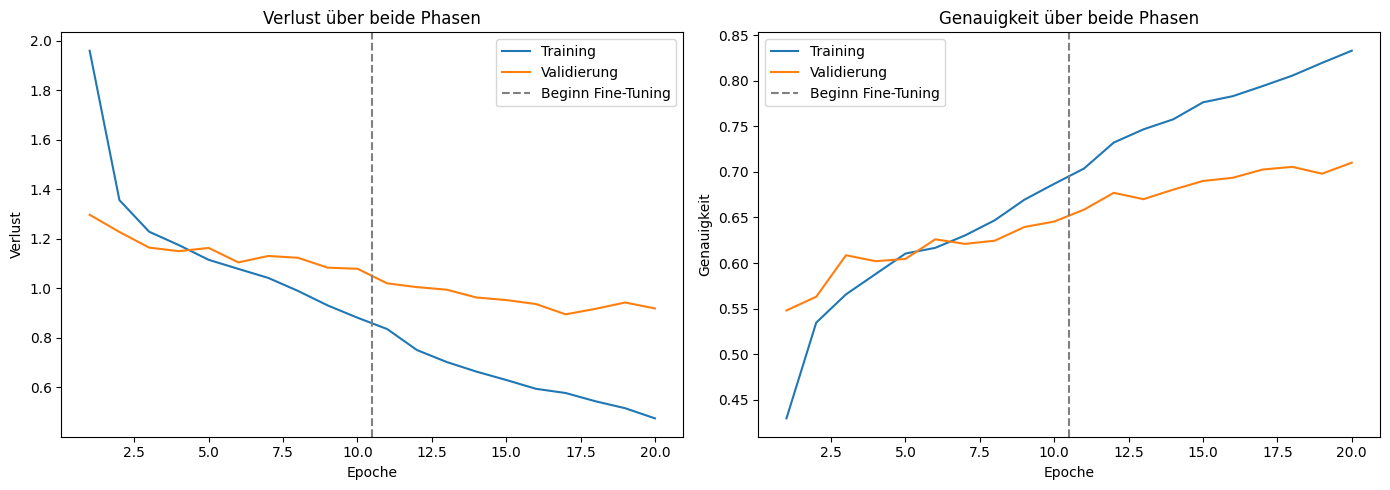

In [8]:
def combine_history_values(metric):
    return head_history.history[metric] + fine_tune_history.history[metric]

total_epochs = len(combine_history_values("loss"))
stage_boundary = len(head_history.history["loss"])
epoch_numbers = np.arange(1, total_epochs + 1)

METRIC_LABELS = {"loss": "Verlust", "accuracy": "Genauigkeit"}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for metric, ax in zip(("loss", "accuracy"), axes):
    ax.plot(epoch_numbers, combine_history_values(metric), label="Training")
    ax.plot(epoch_numbers, combine_history_values(f"val_{metric}"), label="Validierung")
    ax.axvline(stage_boundary + 0.5, color="gray", linestyle="--", label="Beginn Fine-Tuning")
    ax.set_xlabel("Epoche")
    ax.set_ylabel(METRIC_LABELS[metric])
    ax.set_title(f"{METRIC_LABELS[metric]} über beide Phasen")
    ax.legend()
plt.tight_layout()

fig.savefig(RESULTS_DIR / "training_history.png", dpi=150)

## 9. Auf dem Testdatensatz evaluieren

Der Testdatensatz wird genau einmal nach Modellauswahl und Fine-Tuning ausgewertet. Verlust und Genauigkeit werden aus einem einzigen Vorhersagedurchlauf berechnet. Die Genauigkeit ist ein nützliches Gesamtmaß, die Konfusionsmatrix zeigt dagegen, welche Klassen schwer zu unterscheiden sind.

157/157 ━━━━━━━━━━━━━━━━━━━━ 6s 26ms/step
Test-Verlust: 0.8959
Test-Genauigkeit: 0.7097


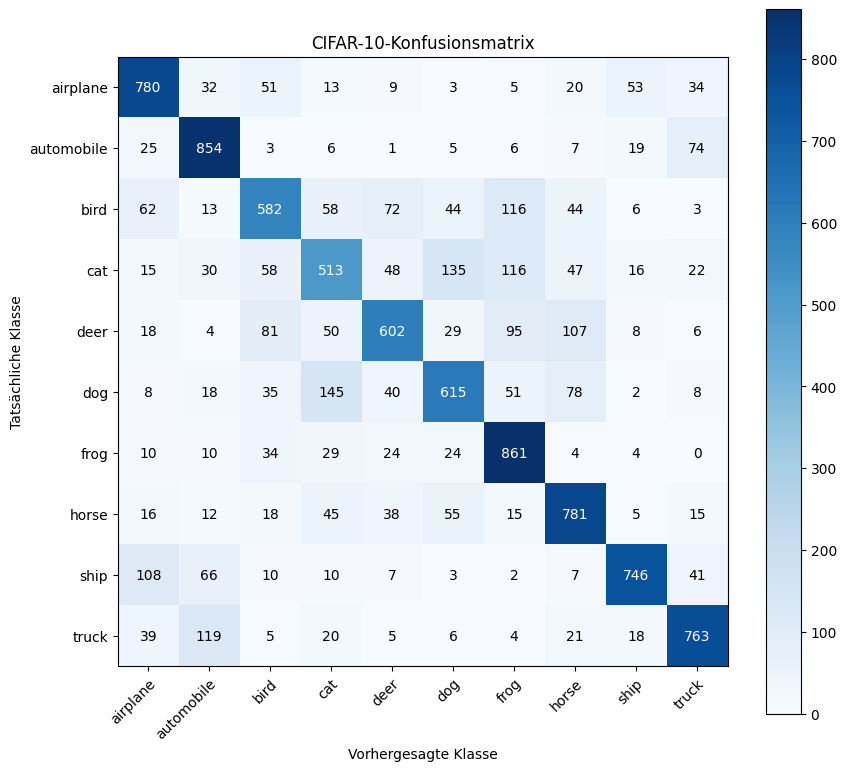

In [9]:
probabilities = model.predict(test_dataset, verbose=1)
predictions = np.argmax(probabilities, axis=1)
test_loss = float(np.mean(
    tf.keras.losses.sparse_categorical_crossentropy(test_labels, probabilities).numpy()
))
test_accuracy = float(np.mean(predictions == test_labels))
print(f"Test-Verlust: {test_loss:.4f}")
print(f"Test-Genauigkeit: {test_accuracy:.4f}")

confusion_matrix = tf.math.confusion_matrix(
    test_labels, predictions, num_classes=len(CLASS_NAMES)
).numpy()

fig, ax = plt.subplots(figsize=(9, 8))
image = ax.imshow(confusion_matrix, cmap="Blues")
fig.colorbar(image, ax=ax)
ax.set(
    xticks=np.arange(len(CLASS_NAMES)),
    yticks=np.arange(len(CLASS_NAMES)),
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    xlabel="Vorhergesagte Klasse",
    ylabel="Tatsächliche Klasse",
    title="CIFAR-10-Konfusionsmatrix"
)
plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
threshold = confusion_matrix.max() / 2
for row in range(confusion_matrix.shape[0]):
    for column in range(confusion_matrix.shape[1]):
        ax.text(
            column, row, confusion_matrix[row, column],
            ha="center", va="center",
            color="white" if confusion_matrix[row, column] > threshold else "black"
        )
fig.tight_layout()

fig.savefig(RESULTS_DIR / "confusion_matrix.png", dpi=150)

## 10. Metriken pro Klasse und Export

Die Gesamtgenauigkeit kann schwache Klassen verdecken. Recall pro Klasse (Genauigkeit innerhalb jeder tatsächlichen Klasse), Präzision und F1 zeigen, wo das Modell Schwierigkeiten hat, und die häufigsten Einträge außerhalb der Diagonale der Konfusionsmatrix benennen die schwierigsten Klassenpaare. Alle Ergebnisse werden in `results/metrics.json` gespeichert.

In [10]:
true_counts = confusion_matrix.sum(axis=1)
predicted_counts = confusion_matrix.sum(axis=0)
correct = confusion_matrix.diagonal()
recall = correct / true_counts
precision = np.divide(correct, predicted_counts, out=np.zeros(len(CLASS_NAMES)), where=predicted_counts > 0)
f1 = np.divide(2 * precision * recall, precision + recall, out=np.zeros(len(CLASS_NAMES)), where=(precision + recall) > 0)
macro_accuracy = float(recall.mean())

print(f"{'Klasse':<12}{'Genauigk.':>10}{'Präzision':>11}{'F1':>8}")
for class_id in np.argsort(recall)[::-1]:
    print(f"{CLASS_NAMES[class_id]:<12}{recall[class_id]:>10.3f}{precision[class_id]:>11.3f}{f1[class_id]:>8.3f}")
print(f"\nMakro-gemittelte Klassengenauigkeit: {macro_accuracy:.4f}")

off_diagonal = confusion_matrix.copy()
np.fill_diagonal(off_diagonal, 0)
top_confusions = []
print("\nHäufigste Verwechslungen (tatsächlich -> vorhergesagt):")
for flat_index in np.argsort(off_diagonal, axis=None)[::-1][:5]:
    true_id, predicted_id = divmod(int(flat_index), len(CLASS_NAMES))
    count = int(off_diagonal[true_id, predicted_id])
    top_confusions.append({"true": CLASS_NAMES[true_id], "predicted": CLASS_NAMES[predicted_id], "count": count})
    print(f"  {CLASS_NAMES[true_id]} -> {CLASS_NAMES[predicted_id]}: {count}")


def summarize_stage(history):
    values = history.history
    best_epoch = int(np.argmin(values["val_loss"]))
    return {
        "epochs_run": len(values["loss"]),
        "best_epoch": best_epoch + 1,
        "best_val_loss": float(values["val_loss"][best_epoch]),
        "val_accuracy_at_best": float(values["val_accuracy"][best_epoch]),
    }


metrics = {
    "train_samples": int(len(train_labels)),
    "fit_samples": int(len(fit_labels)),
    "validation_samples": int(len(validation_labels)),
    "test_samples": int(len(test_labels)),
    "image_size": IMAGE_SIZE,
    "head_stage": summarize_stage(head_history),
    "fine_tune_stage": summarize_stage(fine_tune_history),
    "test_loss": test_loss,
    "test_accuracy": test_accuracy,
    "macro_accuracy": macro_accuracy,
    "per_class": {
        name: {"accuracy": float(recall[i]), "precision": float(precision[i]), "f1": float(f1[i])}
        for i, name in enumerate(CLASS_NAMES)
    },
    "top_confusions": top_confusions,
    "confusion_matrix": confusion_matrix.tolist(),
}
metrics_path = RESULTS_DIR / "metrics.json"
metrics_path.write_text(json.dumps(metrics, indent=2))
print(f"\nMetriken gespeichert unter {metrics_path.resolve()}")

Klasse       Genauigk.  Präzision      F1
frog             0.861      0.677   0.758
automobile       0.854      0.737   0.791
horse            0.781      0.700   0.738
airplane         0.780      0.722   0.750
truck            0.763      0.790   0.776
ship             0.746      0.851   0.795
dog              0.615      0.669   0.641
deer             0.602      0.712   0.652
bird             0.582      0.664   0.620
cat              0.513      0.577   0.543

Makro-gemittelte Klassengenauigkeit: 0.7097

Häufigste Verwechslungen (tatsächlich -> vorhergesagt):
  dog -> cat: 145
  cat -> dog: 135
  truck -> automobile: 119
  cat -> frog: 116
  bird -> frog: 116

Metriken gespeichert unter /content/results/metrics.json


## 11. Analyse

### Vorverarbeitung

`preprocess_input` wendet dieselbe Transformation an, die beim Training von ResNet50 auf ImageNet verwendet wurde: Sie wandelt RGB in BGR um und zieht die ImageNet-Mittelwerte pro Farbkanal ab. Die vortrainierten Filter erwarten Eingaben in diesem Wertebereich. Rohe Pixelwerte von 0-255 oder 0-1 würden die übertragenen Merkmale schwächen. CIFAR-10-Bilder haben bereits die Form 32x32x3, die die Vorgabe als Eingabeform festlegt, daher wird die Größe nicht verändert. Der Testdatensatz wird genauso vorverarbeitet, aber nie für Training oder Modellauswahl verwendet.

### Warum zwei Trainingsphasen

Der neue Kopf startet mit zufälligen Gewichten. Würde das gesamte Netz von Anfang an trainiert, flössen die großen Gradienten dieses zufälligen Kopfes in die vortrainierten Schichten und würden nützliche Merkmale zerstören. Wird zuerst nur der Kopf auf den eingefrorenen Merkmalen trainiert (Lernrate 1e-3, etwa 0,5 Mio. trainierbare Parameter), erhält er einen sinnvollen Ausgangspunkt. Beim Fine-Tuning werden anschließend die Faltungsschichten (etwa 23,5 Mio. Parameter) mit einer 100-mal kleineren Lernrate freigegeben, sodass sich die Merkmale behutsam an CIFAR-10 anpassen.

### Was im ersten Durchlauf schiefging

Der erste Durchlauf erreichte **47,0 % Testgenauigkeit**, obwohl die Kopf-Phase allein bereits **62,1 % Validierungsgenauigkeit** erreicht hatte. Das Fine-Tuning hat das Modell verschlechtert. Die Kopf-Phase lief 8 Epochen; Early Stopping stellte danach die Gewichte der besten Epoche 4 wieder her, mit denen das Fine-Tuning startete. Die 88 % Trainingsgenauigkeit aus Epoche 8 waren also nicht der Ausgangspunkt des Fine-Tunings:

| Phase | Trainingsgenauigkeit | Validierungsgenauigkeit |
| --- | --- | --- |
| Kopf-Phase, beste Epoche (4) | 71 % | 62,1 % |
| Fine-Tuning, Epoche 1 | 32 % | 48,1 % |
| Fine-Tuning, Epoche 4 (finales Modell) | 46 % | 44,8 % |

Zwei Ursachen wurden identifiziert:

1. **Einbruch durch Batch Normalization.** Die Trainingsgenauigkeit fiel in der ersten Fine-Tuning-Epoche von 71 % (wiederhergestellte Kopf-Epoche 4) auf 32 %, obwohl die Lernrate nur 1e-5 betrug. Ein so plötzlicher und starker Einbruch deutet darauf hin, dass die Batch-Normalization-Schichten auf die Statistiken des jeweiligen Batches umgeschaltet haben. Bei 32x32-Eingaben sehen die tiefsten Blöcke 1x1-Merkmalskarten, daher sind diese Statistiken sehr verrauscht und überschreiben die gleitenden Mittelwerte aus ImageNet. Diese Version hält alle Batch-Normalization-Schichten eingefroren.
2. **Gemeinsam genutzte Callbacks.** Beide Phasen verwendeten dasselbe `EarlyStopping`-Objekt. Es behielt den besten Validierungsverlust der Kopf-Phase (1,116), sodass keine Fine-Tuning-Epoche als Verbesserung zählte. Das Fine-Tuning brach nach genau 4 Epochen ab (dem Patience-Wert), und da keine „besten“ Gewichte gespeichert waren, blieb das schwächste Modell erhalten. Diese Version erzeugt für jede Phase neue Callbacks.

Der erste Durchlauf zeigte außerdem deutliches Overfitting in der Kopf-Phase: Bis Epoche 8 stieg die Trainingsgenauigkeit auf 88 %, während die Validierungsgenauigkeit bei etwa 63 % blieb. Um dem entgegenzuwirken, wurde Datenaugmentation ergänzt.

### Ergebnisse dieses Durchlaufs

> **Hinweis:** Die Zahlen in diesem Abschnitt und die Dateien in `results/` stammen aus dem finalen Colab-Durchlauf (Testgenauigkeit 70,88 %). Falls die Zellausgaben oben andere Werte zeigen, stammen sie aus einer früheren Ausführung. Die Kopf-Phase ist in beiden Ausführungen identisch, das Fine-Tuning auf der GPU ist trotz Seed nicht vollständig deterministisch.

- **Beste Validierungsgenauigkeit der Kopf-Phase:** 64,55 % (Epoche 10)
- **Validierungsgenauigkeit beim Fine-Tuning:** höchster Wert rund 71 % in Epoche 10. Das ist auch das ausgewertete Modell. *Das Fine-Tuning hat die Kopf-Phase also deutlich übertroffen (rund +6,5 Prozentpunkte).*
- **Hinweis zur „besten“ Epoche:** Der niedrigste Validierungs*verlust* lag in Epoche 7 (0,9119 bei 69,85 % Genauigkeit). Diese Epoche meldet `metrics.json` als `best_epoch`, weil Early Stopping und `summarize_stage` nach `val_loss` auswählen. Early Stopping hat aber nicht ausgelöst (nach Epoche 7 nur 3 Epochen ohne Verbesserung, Patience 4), deshalb hat `restore_best_weights` nichts wiederhergestellt. Getestet werden die Gewichte nach Epoche 10.
- **Test-Verlust / Test-Genauigkeit:** 0,9039 / 70,88 %
- **Makro-gemittelte Klassengenauigkeit:** 70,88 %. Sie ist identisch mit der Testgenauigkeit, weil der Testdatensatz genau 1.000 Bilder pro Klasse enthält; der Mittelwert der Klassen-Recalls ist dann gleich der Gesamtgenauigkeit.
- **Stärkste und schwächste Klassen:** Stärkste: `automobile` (86,6 %), `frog` (86,1 %); Schwächste: `cat` (50,8 %), `deer` (59,1 %), `bird` (59,5 %)
- **Am häufigsten verwechselte Klassenpaare:** `cat -> dog` (140), `dog -> cat` (140), `truck -> automobile` (132), `cat -> frog` (118), `ship -> airplane` (116)
- **Auffällig:** `frog` hat einen der höchsten Recalls (86,1 %), aber nur 67,1 % Präzision. Das Modell sagt „frog“ zu oft vorher, vor allem für Katzen (118), Vögel (115) und Rehe (98).
- **Overfitting:** Die Validierungsgenauigkeit folgt der Trainingskurve recht stabil und steigt beim Fine-Tuning kontinuierlich mit an. Die Lücke zwischen Trainings- und Validierungsleistung bleibt dank Datenaugmentation und Dropout moderat (am Ende rund 83 % Training zu 71 % Validierung, also etwa 12 Prozentpunkte).

### Einschränkungen

- **Daten:** Nur 10.000 der 50.000 Trainingsbilder werden verwendet, und 2.000 davon dienen der Validierung. Das Modell lernt also aus 8.000 Bildern.
- **Auflösung und Domäne:** ResNet50 hat seine Merkmale auf ImageNet-Fotos mit 224x224 Pixeln gelernt. Bei 32x32 ist die letzte Merkmalskarte des Netzes nur 1x1 groß, was dem Klassifikator sehr wenig räumliche Information lässt.
- **Hardware und Laufzeit:** Das Fine-Tuning aller 23,5 Mio. Parameter ist ohne GPU langsam. Auf der lokalen CPU benötigte der erste Durchlauf etwa 3-4 Minuten pro Fine-Tuning-Epoche, und TensorFlow unterstützt unter Windows keine native GPU-Nutzung. Dieser Durchlauf lief deshalb in Google Colab auf einer GPU (etwa 8 Sekunden pro Fine-Tuning-Epoche).
- **Trainingsbudget:** Die Vorgabe begrenzt jede Phase auf 10 Epochen, was für das Fine-Tuning eines Netzes dieser Größe kurz ist.

### Mögliche nächste Schritte

- Die Eingaben im Modell hochskalieren (`IMAGE_SIZE = 96` oder größer). Das ist voraussichtlich die größte einzelne Verbesserung, kostet aber viel Laufzeit.
- Stärkere Augmentation verwenden (zufällige Ausschnitte, Farbvariationen, Mixup oder Cutout).
- Mehr der 50.000 Trainingsbilder nutzen.
- Schrittweise freigeben: zuerst nur den letzten ResNet-Block feinabstimmen, danach frühere Blöcke.
- Länger trainieren, mit einem Lernraten-Zeitplan wie Cosine Decay.
- Mit einer kleineren Architektur für 32x32-Bilder vergleichen, etwa einem CIFAR-ResNet.